## Problema 2 — Rede MLP para Detecção de Ataques em Redes de Computadores

Classificação de conexões de redes como normais ou ataques utilizando o dataset NSL-KDD

### 1. Importação das bibliotecas

In [1]:
from pathlib import Path
from copy import deepcopy

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Versão do PyTorch:", torch.__version__)
print("Dispositivo utilizado:", device)

Versão do PyTorch: 2.15.0+cpu
Dispositivo utilizado: cpu


### 2. Carregamento e análise exploratória do dataset

In [3]:
col_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised", 
    "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count", 
    "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", 
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate", 
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "attack_type", "difficulty_level"
]

print("Quantidade de colunas:", len(col_names))

Quantidade de colunas: 43


In [4]:
project_dir = Path.cwd()

if project_dir.name != "projeto_02_mlp":
    project_dir = project_dir / "projeto_02_mlp"

data_dir = project_dir / "data"
figures_dir = project_dir / "figuras"

figures_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(
    data_dir / "KDDTrain+.txt",
    header=None,
    names=col_names
)

test_df = pd.read_csv(
    data_dir / "KDDTest+.txt",
    header=None,
    names=col_names
)

print("Dimensões do conjunto de treino:", train_df.shape)
print("Dimensões do conjunto de teste:", test_df.shape)

display(train_df.head())

Dimensões do conjunto de treino: (125973, 43)
Dimensões do conjunto de teste: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack_type,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [5]:
print("Valores ausentes no treino:")
print(train_df.isnull().sum().sum())

print("\nValores ausentes no teste:")
print(test_df.isnull().sum().sum())

print("\nTipos de dados:")
print(train_df.dtypes)

print("\nDistribuição dos tipos de conexão:")
print(train_df["attack_type"].value_counts())

Valores ausentes no treino:
0

Valores ausentes no teste:
0

Tipos de dados:
duration                         int64
protocol_type                      str
service                            str
flag                               str
src_bytes                        int64
dst_bytes                        int64
land                             int64
wrong_fragment                   int64
urgent                           int64
hot                              int64
num_failed_logins                int64
logged_in                        int64
num_compromised                  int64
root_shell                       int64
su_attempted                     int64
num_root                         int64
num_file_creations               int64
num_shells                       int64
num_access_files                 int64
num_outbound_cmds                int64
is_host_login                    int64
is_guest_login                   int64
count                            int64
srv_count                 

### 3. Pré-processamento dos dados

In [6]:
train_df = train_df.drop(columns=["difficulty_level"])
test_df = test_df.drop(columns=["difficulty_level"])

print("Dimensões do treino:", train_df.shape)
print("Dimensões do teste:", test_df.shape)

Dimensões do treino: (125973, 42)
Dimensões do teste: (22544, 42)


In [7]:
train_df["attack_type"] = (
    train_df["attack_type"] != "normal"
).astype(int)

test_df["attack_type"] = (
    test_df["attack_type"] != "normal"
).astype(int)

print("Distribuição das classes no treino:")
print(train_df["attack_type"].value_counts().sort_index())

print("\nDistribuição das classes no teste:")
print(test_df["attack_type"].value_counts().sort_index())

Distribuição das classes no treino:
attack_type
0    67343
1    58630
Name: count, dtype: int64

Distribuição das classes no teste:
attack_type
0     9711
1    12833
Name: count, dtype: int64


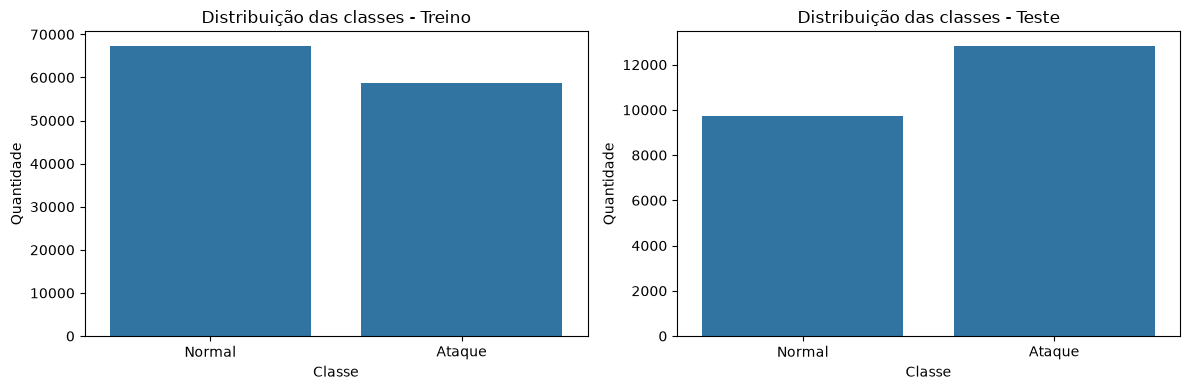

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=train_df,
    x="attack_type",
    ax=axes[0]
)

axes[0].set_title("Distribuição das classes - Treino")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Quantidade")
axes[0].set_xticks([0, 1], ["Normal", "Ataque"])

sns.countplot(
    data=test_df,
    x="attack_type",
    ax=axes[1]
)

axes[1].set_title("Distribuição das classes - Teste")
axes[1].set_xlabel("Classe")
axes[1].set_ylabel("Quantidade")
axes[1].set_xticks([0, 1], ["Normal", "Ataque"])

plt.tight_layout()

plt.savefig(
    figures_dir / "01_distribuicao_classes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
X = train_df.drop(columns=["attack_type"])
y = train_df["attack_type"]

X_test = test_df.drop(columns=["attack_type"])
y_test = test_df["attack_type"]

print("Atributos de entrada:", X.shape[1])

Atributos de entrada: 41


In [10]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

Treinamento: (100778, 41)
Validação: (25195, 41)
Teste: (22544, 41)


In [11]:
categorical_cols = [
    "protocol_type",
    "service",
    "flag"
]

numerical_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

print("Atributos categóricos:", len(categorical_cols))
print("Atributos numéricos:", len(numerical_cols))

Atributos categóricos: 3
Atributos numéricos: 38


In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_cols
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

print("Treino:", X_train_processed.shape)
print("Validação:", X_val_processed.shape)
print("Teste:", X_test_processed.shape)

Treino: (100778, 121)
Validação: (25195, 121)
Teste: (22544, 121)


In [13]:
n_numeric = len(numerical_cols)

numeric_train = X_train_processed[:, :n_numeric]

numeric_stats = pd.DataFrame({
    "Atributo": numerical_cols,
    "Média": numeric_train.mean(axis=0),
    "Desvio padrão": numeric_train.std(axis=0)
})

display(numeric_stats.round(6))

,Atributo,Média,Desvio padrão
0,duration,-0.0,1.0
1,src_bytes,0.0,1.0
2,dst_bytes,-0.0,1.0
3,land,-0.0,1.0
4,wrong_fragment,0.0,1.0
5,urgent,0.0,1.0
6,hot,0.0,1.0
7,num_failed_logins,0.0,1.0
8,logged_in,-0.0,1.0
9,num_compromised,-0.0,1.0


### 4. Preparação dos dados para o PyTorch

In [14]:
X_train_tensor = torch.tensor(
    X_train_processed, dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_processed, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_processed, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(), dtype=torch.float32
)

print("Treino:", X_train_tensor.shape, y_train_tensor.shape)
print("Validação:", X_val_tensor.shape, y_val_tensor.shape)
print("Teste:", X_test_tensor.shape, y_test_tensor.shape)

Treino: torch.Size([100778, 121]) torch.Size([100778])
Validação: torch.Size([25195, 121]) torch.Size([25195])
Teste: torch.Size([22544, 121]) torch.Size([22544])


In [15]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

print("Amostras de treinamento:", len(train_dataset))
print("Amostras de validação:", len(val_dataset))
print("Amostras de teste:", len(test_dataset))

Amostras de treinamento: 100778
Amostras de validação: 25195
Amostras de teste: 22544


In [16]:
BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Mini-batches de treino:", len(train_loader))
print("Mini-batches de validação:", len(val_loader))
print("Mini-batches de teste:", len(test_loader))

Mini-batches de treino: 394
Mini-batches de validação: 99
Mini-batches de teste: 89


In [17]:
X_batch, y_batch = next(iter(train_loader))

print("Dimensão dos atributos:", X_batch.shape)
print("Dimensão dos rótulos:", y_batch.shape)

print("\nTipo dos atributos:", X_batch.dtype)
print("Tipo dos rótulos:", y_batch.dtype)

Dimensão dos atributos: torch.Size([256, 121])
Dimensão dos rótulos: torch.Size([256])

Tipo dos atributos: torch.float32
Tipo dos rótulos: torch.float32


### 5. Implementação da Rede Neural MLP

In [18]:
class MLP(nn.Module):

    def __init__(self, input_size, hidden_sizes):
        super().__init__()

        layers = []
        previous_size = input_size

        for hidden_size in hidden_sizes:

            layers.append(
                nn.Linear(previous_size, hidden_size)
            )

            layers.append(nn.ReLU())

            previous_size = hidden_size

        layers.append(
            nn.Linear(previous_size, 1)
        )

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x).squeeze(-1)

In [19]:
input_size = X_train_tensor.shape[1]

architectures = {
    "MLP_1": [64],
    "MLP_2": [128, 64],
    "MLP_3": [256, 128, 64]
}

print("Quantidade de neurônios de entrada:", input_size)

for name, hidden_sizes in architectures.items():
    print(f"{name}: {hidden_sizes}")

Quantidade de neurônios de entrada: 121
MLP_1: [64]
MLP_2: [128, 64]
MLP_3: [256, 128, 64]


In [20]:
models = {}

for name, hidden_sizes in architectures.items():

    torch.manual_seed(SEED)

    model = MLP(
        input_size=input_size,
        hidden_sizes=hidden_sizes
    ).to(device)

    models[name] = model

    print(f"\n{name}")
    print(model)

    total_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print("Parâmetros treináveis:", total_params)


MLP_1
MLP(
  (network): Sequential(
    (0): Linear(in_features=121, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parâmetros treináveis: 7873

MLP_2
MLP(
  (network): Sequential(
    (0): Linear(in_features=121, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parâmetros treináveis: 23937

MLP_3
MLP(
  (network): Sequential(
    (0): Linear(in_features=121, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parâmetros treináveis: 72449


#### 5.1. Função de perda e otimizador

In [21]:
LEARNING_RATE = 0.001
EPOCHS = 50

criterion = nn.BCEWithLogitsLoss()

optimizers = {
    name: torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )
    for name, model in models.items()
}

print("Função de perda:", criterion)
print("Otimizador: Adam")
print("Taxa de aprendizagem:", LEARNING_RATE)
print("Número de épocas:", EPOCHS)
print("Batch size:", BATCH_SIZE)

Função de perda: BCEWithLogitsLoss()
Otimizador: Adam
Taxa de aprendizagem: 0.001
Número de épocas: 50
Batch size: 256


In [22]:
X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

for name, model in models.items():

    model.eval()

    with torch.no_grad():

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

    print(f"\nModelo: {name}")
    print("Dimensão da saída:", logits.shape)
    print("Dimensão dos rótulos:", y_batch.shape)
    print(f"Loss inicial: {loss.item():.6f}")


Modelo: MLP_1
Dimensão da saída: torch.Size([256])
Dimensão dos rótulos: torch.Size([256])
Loss inicial: 0.702705

Modelo: MLP_2
Dimensão da saída: torch.Size([256])
Dimensão dos rótulos: torch.Size([256])
Loss inicial: 0.704560

Modelo: MLP_3
Dimensão da saída: torch.Size([256])
Dimensão dos rótulos: torch.Size([256])
Loss inicial: 0.686285


### 6. Treinamento e monitoramento

In [23]:
def train_epoch(model, loader, criterion, optimizer):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)
        total_samples += X_batch.size(0)

    return total_loss / total_samples

In [24]:
def validate_epoch(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)

            loss = criterion(logits, y_batch)

            total_loss += loss.item() * X_batch.size(0)
            total_samples += X_batch.size(0)

    return total_loss / total_samples

In [25]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=50
):

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = None

    for epoch in range(epochs):

        train_loss = train_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_loss = validate_epoch(
            model,
            val_loader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_weights = deepcopy(
                model.state_dict()
            )

        print(
            f"Época [{epoch + 1:02d}/{epochs}] | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {val_loss:.6f}"
        )

    model.load_state_dict(best_weights)

    return {
        "history": history,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "best_weights": best_weights
    }

In [26]:
results = {}

for name, hidden_sizes in architectures.items():

    print("\n" + "=" * 65)
    print(f"TREINAMENTO DO MODELO: {name}")
    print(f"Camadas ocultas: {hidden_sizes}")
    print("=" * 65)

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = MLP(
        input_size=input_size,
        hidden_sizes=hidden_sizes
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    models[name] = model
    optimizers[name] = optimizer

    results[name] = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        epochs=EPOCHS
    )

    print(f"\nMelhor época: {results[name]['best_epoch']}")

    print(
        f"Menor loss de validação: "
        f"{results[name]['best_val_loss']:.6f}"
    )


TREINAMENTO DO MODELO: MLP_1
Camadas ocultas: [64]
Época [01/50] | Train Loss: 0.144811 | Val Loss: 0.063036
Época [02/50] | Train Loss: 0.050091 | Val Loss: 0.041039
Época [03/50] | Train Loss: 0.035024 | Val Loss: 0.031446
Época [04/50] | Train Loss: 0.028083 | Val Loss: 0.026480
Época [05/50] | Train Loss: 0.024433 | Val Loss: 0.023059
Época [06/50] | Train Loss: 0.022266 | Val Loss: 0.021496
Época [07/50] | Train Loss: 0.020802 | Val Loss: 0.020311
Época [08/50] | Train Loss: 0.019781 | Val Loss: 0.019659
Época [09/50] | Train Loss: 0.018840 | Val Loss: 0.018545
Época [10/50] | Train Loss: 0.017980 | Val Loss: 0.018143
Época [11/50] | Train Loss: 0.017320 | Val Loss: 0.017234
Época [12/50] | Train Loss: 0.016659 | Val Loss: 0.016857
Época [13/50] | Train Loss: 0.016104 | Val Loss: 0.016234
Época [14/50] | Train Loss: 0.015582 | Val Loss: 0.015810
Época [15/50] | Train Loss: 0.015118 | Val Loss: 0.015525
Época [16/50] | Train Loss: 0.014674 | Val Loss: 0.015106
Época [17/50] | Trai

#### 6.1. Análise das curvas de convergência

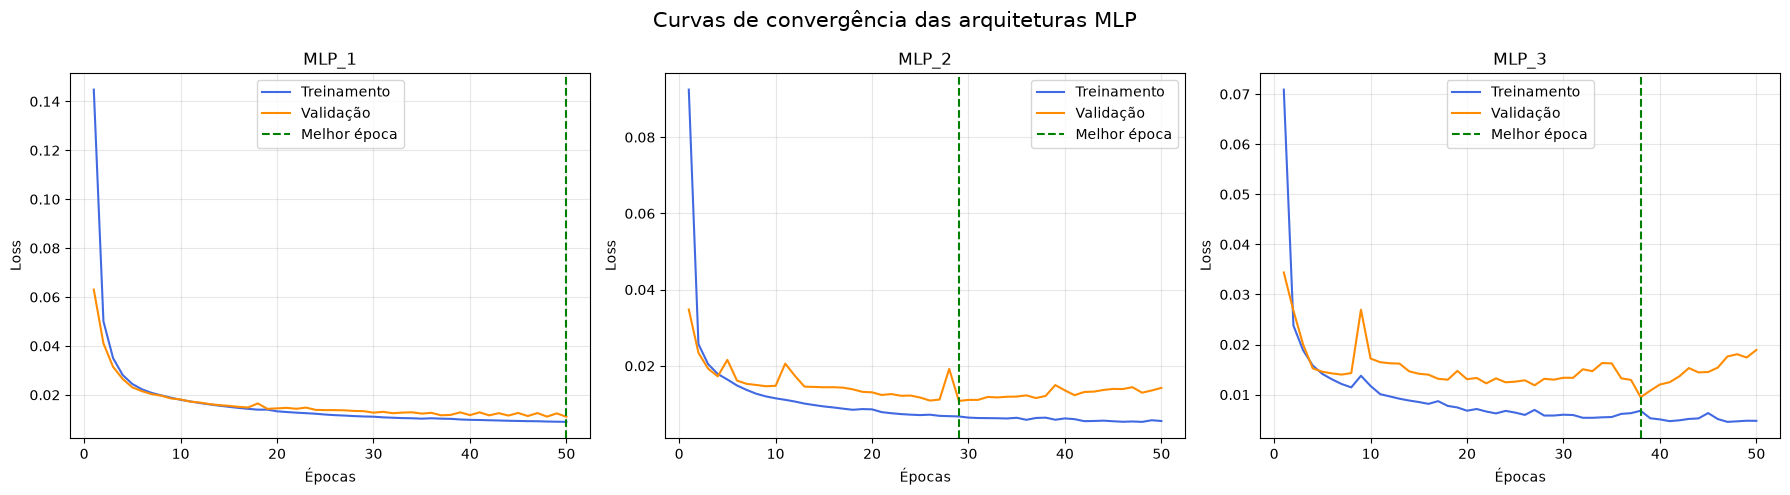

In [27]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, (name, result) in zip(axes, results.items()):

    history = result["history"]

    epochs_range = range(1, EPOCHS + 1)

    ax.plot(
        epochs_range,
        history["train_loss"],
        label="Treinamento",
        color="royalblue"
    )

    ax.plot(
        epochs_range,
        history["val_loss"],
        label="Validação",
        color="darkorange"
    )

    ax.axvline(
        result["best_epoch"],
        color="green",
        linestyle="--",
        label="Melhor época"
    )

    ax.set_title(name)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Loss")

    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Curvas de convergência das arquiteturas MLP",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    figures_dir / "02_curvas_convergencia.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

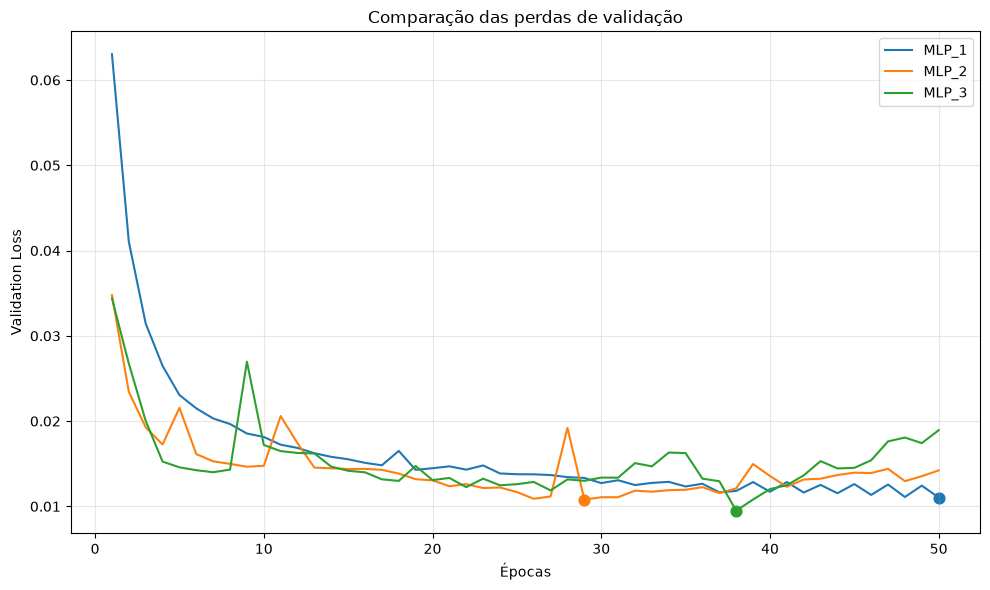

In [28]:
plt.figure(figsize=(10, 6))

for name, result in results.items():

    plt.plot(
        range(1, EPOCHS + 1),
        result["history"]["val_loss"],
        label=name
    )

    plt.scatter(
        result["best_epoch"],
        result["best_val_loss"],
        s=60
    )

plt.title("Comparação das perdas de validação")
plt.xlabel("Épocas")
plt.ylabel("Validation Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "03_comparacao_topologias.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
comparison = []

for name, result in results.items():

    history = result["history"]

    best_index = result["best_epoch"] - 1

    comparison.append({

        "Modelo": name,

        "Camadas ocultas": str(architectures[name]),

        "Parâmetros treináveis": sum(
            p.numel()
            for p in models[name].parameters()
            if p.requires_grad
        ),

        "Train Loss final":
            history["train_loss"][-1],

        "Val Loss final":
            history["val_loss"][-1],

        "Train Loss na melhor época":
            history["train_loss"][best_index],

        "Melhor Val Loss":
            result["best_val_loss"],

        "Melhor época":
            result["best_epoch"]

    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="Melhor Val Loss"
).reset_index(drop=True)

display(comparison_df.round(6))

,Modelo,Camadas ocultas,Parâmetros treináveis,Train Loss final,Val Loss final,Train Loss na melhor época,Melhor Val Loss,Melhor época
0,MLP_3,"[256, 128, 64]",72449,0.004779,0.018933,0.006790,0.009497,38
1,MLP_2,"[128, 64]",23937,0.005531,0.014221,0.006730,0.010798,29
2,MLP_1,[64],7873,0.008955,0.011039,0.008955,0.011039,50


In [30]:
best_model_name = min(
    results,
    key=lambda name: results[name]["best_val_loss"]
)

best_model = models[best_model_name]

best_model.load_state_dict(
    results[best_model_name]["best_weights"]
)

best_model.eval()

print("Melhor arquitetura:", best_model_name)

print(
    "Camadas ocultas:",
    architectures[best_model_name]
)

print(
    "Melhor época:",
    results[best_model_name]["best_epoch"]
)

print(
    "Melhor loss de validação:",
    results[best_model_name]["best_val_loss"]
)

Melhor arquitetura: MLP_3
Camadas ocultas: [256, 128, 64]
Melhor época: 38
Melhor loss de validação: 0.009497362313500828


#### 6.2. Análise da parada antecipada

In [31]:
def analyze_early_stopping(
    val_losses,
    patience=5
):

    best_loss = float("inf")
    best_epoch = 0
    counter = 0

    for epoch, val_loss in enumerate(
        val_losses,
        start=1
    ):

        if val_loss < best_loss:

            best_loss = val_loss
            best_epoch = epoch
            counter = 0

        else:

            counter += 1

        if counter >= patience:

            return {
                "early_stopping": True,
                "stop_epoch": epoch,
                "best_epoch": best_epoch,
                "best_loss": best_loss
            }

    return {
        "early_stopping": False,
        "stop_epoch": len(val_losses),
        "best_epoch": best_epoch,
        "best_loss": best_loss
    }

In [32]:
PATIENCE = 5

early_stopping_results = []

for name, result in results.items():

    analysis = analyze_early_stopping(
        result["history"]["val_loss"],
        patience=PATIENCE
    )

    early_stopping_results.append({

        "Modelo": name,

        "Parada antecipada":
            "Sim" if analysis["early_stopping"] else "Não",

        "Época de interrupção simulada":
            analysis["stop_epoch"],

        "Melhor época antes da parada":
            analysis["best_epoch"],

        "Melhor loss antes da parada":
            analysis["best_loss"],

        "Melhor época nas 50 épocas":
            result["best_epoch"],

        "Melhor loss nas 50 épocas":
            result["best_val_loss"],

        "Épocas economizadas":
            EPOCHS - analysis["stop_epoch"]

    })

early_stopping_df = pd.DataFrame(
    early_stopping_results
)

display(early_stopping_df.round(6))

,Modelo,Parada antecipada,Época de interrupção simulada,Melhor época antes da parada,Melhor loss antes da parada,Melhor época nas 50 épocas,Melhor loss nas 50 épocas,Épocas economizadas
0,MLP_1,Não,50,50,0.011039,50,0.011039,0
1,MLP_2,Sim,34,29,0.010798,29,0.010798,16
2,MLP_3,Sim,12,7,0.014007,38,0.009497,38


In [33]:
model_path = project_dir / "best_mlp.pth"

torch.save(
    {
        "model_name": best_model_name,

        "input_size": input_size,

        "hidden_sizes":
            architectures[best_model_name],

        "model_state_dict":
            results[best_model_name]["best_weights"],

        "best_epoch":
            results[best_model_name]["best_epoch"],

        "best_val_loss":
            results[best_model_name]["best_val_loss"]
    },
    model_path
)

print("Modelo salvo em:", model_path)

Modelo salvo em: c:\Users\peluc\OneDrive\Documentos\Github\Projetos_SI\projeto_02_mlp\best_mlp.pth


### 7. Avaliação final do modelo

In [34]:
best_model.load_state_dict(
    results[best_model_name]["best_weights"]
)

best_model = best_model.to(device)
best_model.eval()

print("Modelo selecionado:", best_model_name)

print(
    "Camadas ocultas:",
    architectures[best_model_name]
)

print(
    "Época selecionada:",
    results[best_model_name]["best_epoch"]
)

print(
    "Loss de validação:",
    results[best_model_name]["best_val_loss"]
)

Modelo selecionado: MLP_3
Camadas ocultas: [256, 128, 64]
Época selecionada: 38
Loss de validação: 0.009497362313500828


In [35]:
def predict_probabilities(model, loader):

    model.eval()

    probabilities = []
    true_labels = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)

            logits = model(X_batch)

            probs = torch.sigmoid(logits)

            probabilities.append(
                probs.cpu().numpy()
            )

            true_labels.append(
                y_batch.cpu().numpy()
            )

    probabilities = np.concatenate(probabilities)

    true_labels = np.concatenate(
        true_labels
    ).astype(int)

    return probabilities, true_labels

In [36]:
test_probabilities, y_true = predict_probabilities(
    best_model,
    test_loader
)

THRESHOLD = 0.5

y_pred = (
    test_probabilities >= THRESHOLD
).astype(int)

print("Quantidade de amostras:", len(y_true))

print("Quantidade de previsões:", len(y_pred))

print("\nPrimeiras 10 probabilidades:")
print(test_probabilities[:10])

print("\nPrimeiras 10 previsões:")
print(y_pred[:10])

print("\nPrimeiros 10 rótulos reais:")
print(y_true[:10])

Quantidade de amostras: 22544
Quantidade de previsões: 22544

Primeiras 10 probabilidades:
[1.00000000e+00 1.00000000e+00 9.96345307e-07 1.00000000e+00
 6.87690545e-07 4.16172981e-07 1.62430219e-02 5.95499091e-02
 1.13497045e-10 7.61467576e-01]

Primeiras 10 previsões:
[1 1 0 1 0 0 0 0 0 1]

Primeiros 10 rótulos reais:
[1 1 0 1 1 0 0 1 0 1]


In [37]:
accuracy = accuracy_score(
    y_true, y_pred
)

precision = precision_score(
    y_true, y_pred,
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Métrica": [
        "Acurácia",
        "Precisão",
        "Recall",
        "F1-score"
    ],

    "Valor": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

metrics_df["Percentual (%)"] = (
    metrics_df["Valor"] * 100
)

display(metrics_df.round(6))

,Métrica,Valor,Percentual (%)
0,Acurácia,0.790055,79.005500
1,Precisão,0.927486,92.748575
2,Recall,0.684719,68.471908
3,F1-score,0.787824,78.782445


In [38]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Normal", "Ataque"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal     0.6904    0.9293    0.7922      9711
      Ataque     0.9275    0.6847    0.7878     12833

    accuracy                         0.7901     22544
   macro avg     0.8090    0.8070    0.7900     22544
weighted avg     0.8254    0.7901    0.7897     22544



#### 7.1. Matriz de confusão

In [39]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

print("Matriz de confusão:")
print(cm)

Matriz de confusão:
[[9024  687]
 [4046 8787]]


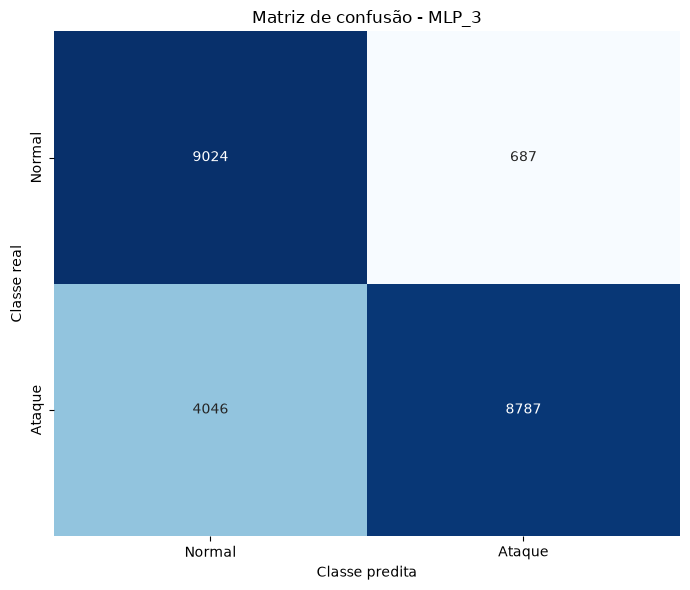

In [40]:
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Ataque"],
    yticklabels=["Normal", "Ataque"],
    cbar=False
)

plt.title(
    f"Matriz de confusão - {best_model_name}"
)

plt.xlabel("Classe predita")
plt.ylabel("Classe real")

plt.tight_layout()

plt.savefig(
    figures_dir / "04_matriz_confusao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
tn, fp, fn, tp = cm.ravel()

print("Verdadeiros negativos:", tn)

print("Falsos positivos:", fp)

print("Falsos negativos:", fn)

print("Verdadeiros positivos:", tp)

print("\nTotal de acertos:", tn + tp)

print("Total de erros:", fp + fn)

print("Total de amostras:", cm.sum())

Verdadeiros negativos: 9024
Falsos positivos: 687
Falsos negativos: 4046
Verdadeiros positivos: 8787

Total de acertos: 17811
Total de erros: 4733
Total de amostras: 22544


In [42]:
false_positive_rate = fp / (fp + tn)

false_negative_rate = fn / (fn + tp)

print(
    f"Taxa de falsos positivos: "
    f"{false_positive_rate:.2%}"
)

print(
    f"Taxa de falsos negativos: "
    f"{false_negative_rate:.2%}"
)

print(
    f"Taxa de detecção de ataques: "
    f"{recall:.2%}"
)

Taxa de falsos positivos: 7.07%
Taxa de falsos negativos: 31.53%
Taxa de detecção de ataques: 68.47%


In [43]:
val_probabilities, y_val_true = predict_probabilities(
    best_model,
    val_loader
)

thresholds = [
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9
]

threshold_results = []

for threshold in thresholds:

    val_pred = (
        val_probabilities >= threshold
    ).astype(int)

    val_cm = confusion_matrix(
        y_val_true,
        val_pred,
        labels=[0, 1]
    )

    val_tn, val_fp, val_fn, val_tp = (
        val_cm.ravel()
    )

    threshold_results.append({

        "Limiar": threshold,

        "Acurácia": accuracy_score(
            y_val_true, val_pred
        ),

        "Precisão": precision_score(
            y_val_true,
            val_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val_true,
            val_pred,
            zero_division=0
        ),

        "F1-score": f1_score(
            y_val_true,
            val_pred,
            zero_division=0
        ),

        "Falsos positivos": val_fp,

        "Falsos negativos": val_fn

    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(threshold_df.round(6))

,Limiar,Acurácia,Precisão,Recall,F1-score,Falsos positivos,Falsos negativos
0,0.1,0.994523,0.989275,0.999062,0.994145,127,11
1,0.2,0.995753,0.991872,0.999062,0.995454,96,11
2,0.3,0.996388,0.993385,0.998891,0.996130,78,13
3,0.4,0.996984,0.995071,0.998465,0.996765,58,18
4,0.5,0.997142,0.996253,0.997612,0.996932,44,28
5,0.6,0.997500,0.997186,0.997442,0.997314,33,30
6,0.7,0.997460,0.997865,0.996674,0.997269,25,39
7,0.8,0.997261,0.998546,0.995565,0.997053,17,52
8,0.9,0.996904,0.998972,0.994371,0.996666,12,66


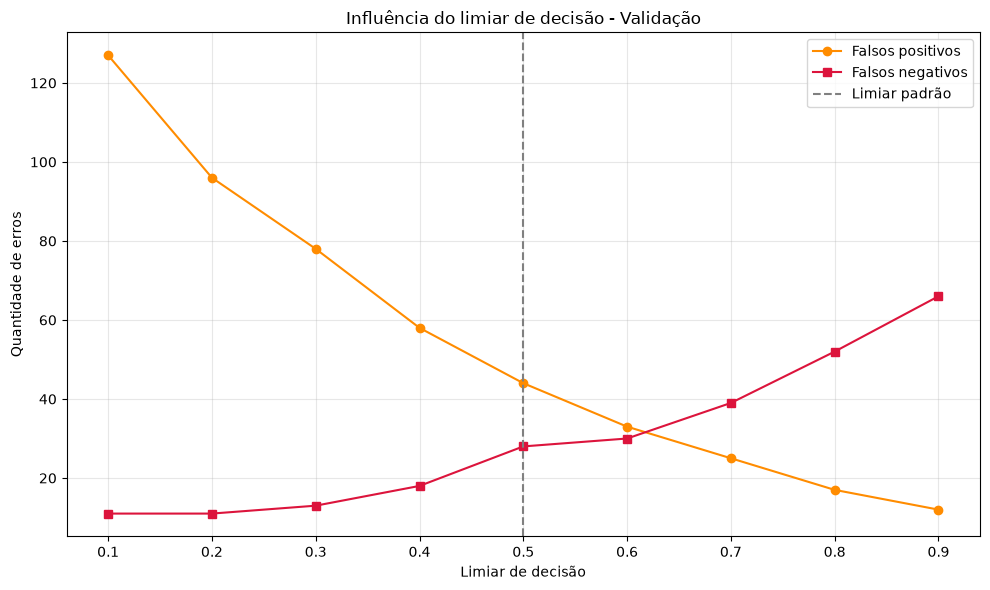

In [44]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Limiar"],
    threshold_df["Falsos positivos"],
    marker="o",
    label="Falsos positivos",
    color="darkorange"
)

plt.plot(
    threshold_df["Limiar"],
    threshold_df["Falsos negativos"],
    marker="s",
    label="Falsos negativos",
    color="crimson"
)

plt.axvline(
    0.5,
    color="gray",
    linestyle="--",
    label="Limiar padrão"
)

plt.title(
    "Influência do limiar de decisão - Validação"
)

plt.xlabel("Limiar de decisão")
plt.ylabel("Quantidade de erros")

plt.xticks(thresholds)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / "05_analise_limiares.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()